In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

In [2]:
def ranked_probability_scores(observations, predictions):
    
    N = len(observations)
    rps = np.zeros(N)
    
    for i in range(N):
        
        observation_prob = np.array([0,0])
        observation_prob[observations[i]] = 1
            
        rps[i] = ( (np.cumsum(predictions[i])-np.cumsum(observation_prob))**2 ).sum()

    return rps

In [3]:
df_features = pd.read_csv('features/features_NE_week3_new.csv')
df_target = pd.read_csv('targets/northern_temperature_10_cat.csv')

In [4]:
df_features['time'] = pd.to_datetime(df_features['time'])
df_features = df_features.set_index('time')

df_target['time'] = pd.to_datetime(df_target['time'])
df_target = df_target.set_index('time')

In [5]:
y_train = df_target[df_target.index < "2010-07"].values[:,0]
y_test = df_target[df_target.index >= "2010-07"].values[:,0]

In [6]:
drop = ['nino3.4_index', 'snow_depth', 'MJO_phase', 'sea_ice_arctic', 'soil_moist_lower', 'sea_ice_baka', 'u10_60N']
df_features_sel = df_features.drop(columns=drop)
len(df_features_sel.columns)

2

In [7]:
X_train = df_features_sel[df_features_sel.index < "2010-07"].values
X_test = df_features_sel[df_features_sel.index >= "2010-07"].values

In [8]:
classifier = RandomForestClassifier(n_estimators=1000, criterion='gini', max_depth=None, min_samples_leaf=1200, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict_proba(X_test)
rps = ranked_probability_scores(y_test, y_pred)

y_climpred = 0.9*np.ones((15*84, 2))
y_climpred[:,1] = 0.1
rps_clim = ranked_probability_scores(y_test, y_climpred)

print(rps.mean())
print(rps_clim.mean())

0.09743956735625547
0.09825396825396825


In [9]:
rpss = 100*(1-rps.mean()/rps_clim.mean())
print(rpss)

0.8288732884637273


In [2]:
rps_valid = 0.0898542955349381
rpss_valid = 100*(1-rps_valid/0.09)
print(rpss_valid)

0.16189385006878387


In [3]:
rps_valid_clim = 0.09055541875852131
rpss_valid_unbiased = 100*(1-rps_valid/rps_valid_clim)
print(rpss_valid_unbiased)

0.7742476741815607


In [11]:
rps_ann = rps.reshape((15,84)).mean(axis=1)
rps_clim_ann = rps_clim.reshape((15,84)).mean(axis=1)

In [12]:
def skill_score(score, ref_score, axis=-1):
    mean = np.mean(score, axis=axis)
    mean_ref = np.mean(ref_score, axis=axis)
    return 1 - mean/mean_ref

In [13]:
skill_score(rps_ann, rps_clim_ann)

np.float64(0.008288732884637162)

In [14]:
res = bootstrap((rps_ann, rps_clim_ann), skill_score, paired=True, confidence_level=0.90, rng=42)

In [15]:
res.confidence_interval

ConfidenceInterval(low=np.float64(-0.010556990370741556), high=np.float64(0.026105409329287323))

In [2]:
regions = ['Northern E.', 'Southwestern E.', 'Southeastern E.']
skills = np.array([0.008288732884637162,0.007992821740750555,0.02287838588398039])*100
lower =  np.array([-0.010556990370741556,-0.013913118386978682,-0.004024215848376399])*100
upper =  np.array([0.026105409329287323,0.029497494468203062,0.050933780622099405])*100

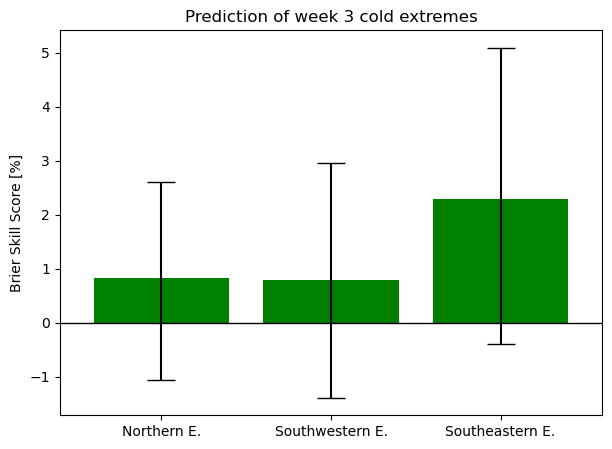

In [3]:
fig, ax = plt.subplots(figsize=(7,5))

ax.bar(regions, skills, yerr=np.stack((skills-lower, upper-skills)), capsize=10, color='green') 
ax.hlines(0, -0.6, 2.6, 'k', linewidths=1)
ax.set_xlim((-0.6, 2.6))
ax.set_ylabel('Brier Skill Score [%]')
ax.set_title('Prediction of week 3 cold extremes')
plt.savefig('coldextr_week3_bars.pdf', bbox_inches = 'tight')

0.0008144008977127729


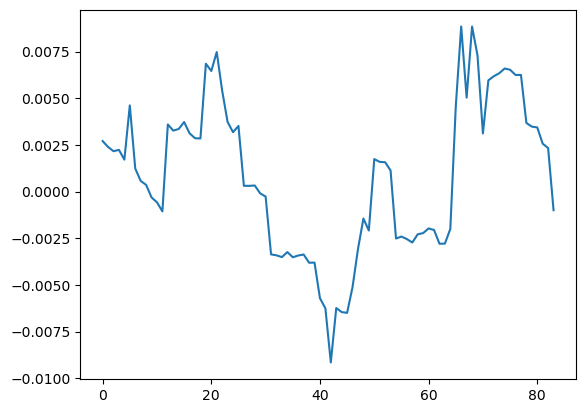

In [16]:
drps_cyc = rps_clim.reshape((15,84)).mean(axis=0) - rps.reshape((15,84)).mean(axis=0)
print(drps_cyc.mean())
plt.plot(drps_cyc)

In [17]:
lofo_rps = np.array([0.09001476364804203, 0.09030929652642904])
lofo_importances = lofo_rps - rps_valid
df_importances = pd.Series(
    lofo_importances, index=df_features_sel.columns
)

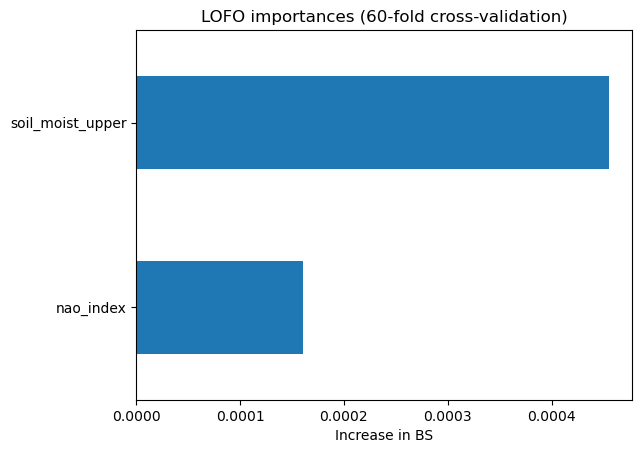

In [18]:
ax = df_importances.plot.barh()
ax.set_title("LOFO importances (60-fold cross-validation)")
ax.set_xlabel("Increase in BS")
plt.savefig('NE_cold_extr_lofo_valid.png', bbox_inches = 'tight')

In [19]:
lofo_rps_test = np.zeros(2)
for i in range(2):

    leave_out = df_features_sel.columns[i]
    df_features_new = df_features_sel.drop(columns=leave_out)
    X_train = df_features_new[df_features_new.index < "2010-07"].values
    X_test = df_features_new[df_features_new.index >= "2010-07"].values
    
    classifier = RandomForestClassifier(n_estimators=1000, criterion='gini', max_depth=None, min_samples_leaf=1200, random_state=42)
    classifier.fit(X_train, y_train)

    y_pred = classifier.predict_proba(X_test)
    rps = ranked_probability_scores(y_test, y_pred)
    lofo_rps_test[i] = rps.mean()

In [20]:
lofo_importances_test = lofo_rps_test - 0.09743956735625547
df_importances_test = pd.Series(
    lofo_importances_test, index=df_features_sel.columns
)

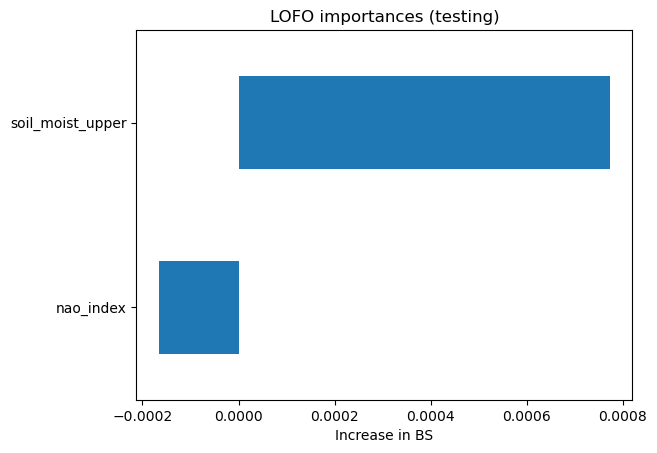

In [22]:
ax = df_importances_test.plot.barh()
ax.set_title("LOFO importances (testing)")
ax.set_xlabel("Increase in BS")
plt.savefig('NE_cold_extr_lofo_test.png', bbox_inches = 'tight')